
# COU 07506 – Digital Signal Processing

## Week 2: Lab 1A – Sampling, Aliasing and Quantization

**Student Name:** Emmanuel Joel Nzavilo

**Registration Number:** 250242455079

**Academic Year:** 2026/2027

**Semester:** I

**Laboratory:** Week 2



## Pre-lab Preparation

### Question 1

A 7 kHz sinusoidal signal is sampled at 10 kHz.

The alias frequency is calculated using:

f_alias = |f0 - k*fs|

Taking k = 1:

f_alias = |7 - 10| = 3 kHz

Therefore, the apparent frequency is 3 kHz.

### Question 2

Given:

- Quantizer resolution: B = 8 bits
- Full-scale range: ±1 V
- Xm = 1 V

The quantization step size is:

Delta = 2Xm / 2^B

Delta = 2(1) / 2^8

Delta = 0.0078125 V

The theoretical SQNR is:

SQNR = 6.02B + 1.76

SQNR = 6.02(8) + 1.76

SQNR = 49.92 dB

Therefore:
- Quantization step size = 0.0078125 V
- Theoretical SQNR = 49.92 dB


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

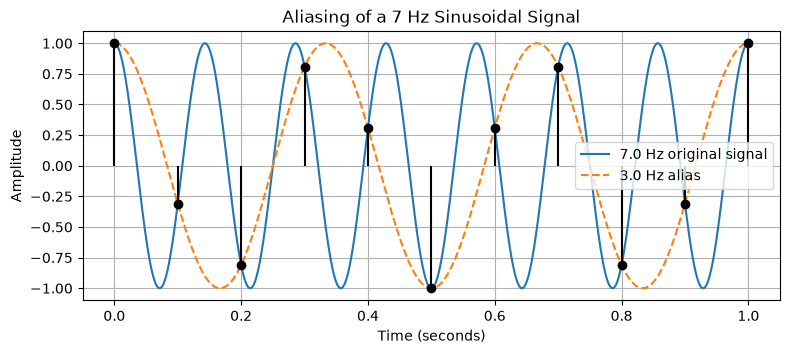

In [2]:
# Original signal frequency and sampling frequency
f0 = 7.0
fs = 10.0

# Create a dense time grid
t = np.linspace(0, 1, 2000)

# Create discrete sample positions
n = np.arange(0, int(fs) + 1)

# Convert sample positions into time
tn = n / fs

# Calculate alias frequency
f_alias = abs(f0 - fs * round(f0 / fs))

# Plot original signal
plt.plot(t, np.cos(2*np.pi*f0*t),
         label=f"{f0} Hz original signal")

# Plot alias signal
plt.plot(t, np.cos(2*np.pi*f_alias*t),
         "--", label=f"{f_alias} Hz alias")

# Plot sampled points
plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

# Add graph labels
plt.title("Aliasing of a 7 Hz Sinusoidal Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# Original signal frequency
f0 = 7.0

# Test different sampling frequencies
sampling_frequencies = [12, 14, 20]

for fs in sampling_frequencies:

    # Calculate alias frequency
    f_alias = abs(f0 - fs * round(f0 / fs))

    print("Sampling Frequency:", fs, "Hz")
    print("Nyquist Frequency:", fs / 2, "Hz")
    print("Alias Frequency:", f_alias, "Hz")
    print("-------------------------")
    

Sampling Frequency: 12 Hz
Nyquist Frequency: 6.0 Hz
Alias Frequency: 5.0 Hz
-------------------------
Sampling Frequency: 14 Hz
Nyquist Frequency: 7.0 Hz
Alias Frequency: 7.0 Hz
-------------------------
Sampling Frequency: 20 Hz
Nyquist Frequency: 10.0 Hz
Alias Frequency: 7.0 Hz
-------------------------


### Task 2.1: Aliasing Frequency Results

The original signal frequency was kept constant at 7 Hz while
the sampling frequency was varied.

| Sampling Frequency (Hz) | Nyquist Frequency (Hz) | Alias Frequency (Hz) |
|---:|---:|---:|
| 10 | 5 | 3 |
| 12 | 6 | 5 |
| 14 | 7 | 7 |
| 20 | 10 | 7 |

### Observation

When the sampling frequency is low, the original 7 Hz signal
may appear at a different frequency due to aliasing.

At a sampling frequency of 10 Hz, the 7 Hz signal appears
as a 3 Hz signal.

At 20 Hz, the Nyquist frequency is 10 Hz, which is greater
than the original signal frequency. Therefore, aliasing does
not occur.

At 14 Hz, the signal is exactly at the Nyquist frequency.

### Task 2.2: Aliasing in Real Audio

In this task, a recorded voice signal is used to investigate
the effects of downsampling with and without anti-aliasing
filtering.

The original audio signal is sampled at 44,100 Hz.

In [4]:
# Import the Audio display tool
from IPython.display import Audio, display

# Specify the audio file name
fname = "myvoice.wav"

# Check whether the audio file exists
import os

if os.path.exists(fname):

    # Read the audio file
    fs, x = wavfile.read(fname)

    # Convert stereo audio to mono if necessary
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Convert audio samples to floating-point values
    x = x.astype(float)

    # Normalize the audio signal
    x = x / np.max(np.abs(x))

    # Calculate audio duration
    duration = len(x) / fs

    # Display audio information
    print("Audio loaded successfully!")
    print("Sampling Frequency:", fs, "Hz")
    print("Number of Samples:", len(x))
    print("Duration:", duration, "seconds")

else:
    print("Audio file not found. Check the file location.")

Audio loaded successfully!
Sampling Frequency: 44100 Hz
Number of Samples: 225792
Duration: 5.12 seconds


### Experiment 1: Naive Downsampling

Naive downsampling reduces the sampling rate by selecting
every kth sample without applying an anti-aliasing filter.

This may introduce aliasing because high-frequency
components are not removed before downsampling.

In [5]:
# Test different downsampling factors
for k in [2, 4, 8]:

    # Select every kth sample without filtering
    naive = x[::k]

    # Calculate the new sampling frequency
    new_fs = fs // k

    # Display the results
    print("Downsampling factor:", k)
    print("New sampling frequency:", new_fs, "Hz")
    print("New number of samples:", len(naive))
    print("-----------------------------")

Downsampling factor: 2
New sampling frequency: 22050 Hz
New number of samples: 112896
-----------------------------
Downsampling factor: 4
New sampling frequency: 11025 Hz
New number of samples: 56448
-----------------------------
Downsampling factor: 8
New sampling frequency: 5512 Hz
New number of samples: 28224
-----------------------------


### Experiment 2: Proper Downsampling

Proper downsampling applies an anti-aliasing low-pass filter
before reducing the sampling frequency.

The scipy.signal.decimate() function performs filtering
and downsampling.

In [6]:
# Test different downsampling factors
for k in [2, 4, 8]:

    # Apply anti-aliasing filtering and downsampling
    proper = signal.decimate(x, k, ftype="fir")

    # Calculate the new sampling frequency
    new_fs = fs // k

    # Display the results
    print("Downsampling factor:", k)
    print("New sampling frequency:", new_fs, "Hz")
    print("New number of samples:", len(proper))
    print("-----------------------------")

Downsampling factor: 2
New sampling frequency: 22050 Hz
New number of samples: 112896
-----------------------------
Downsampling factor: 4
New sampling frequency: 11025 Hz
New number of samples: 56448
-----------------------------
Downsampling factor: 8
New sampling frequency: 5512 Hz
New number of samples: 28224
-----------------------------


### Listening Test: Naive vs Proper Downsampling (k = 8)

The original audio is downsampled using two methods:

1. Naive downsampling without filtering.
2. Proper downsampling using an FIR anti-aliasing filter.

Both signals are played at the same new sampling frequency
to compare their audio quality.

In [7]:
# Set downsampling factor
k = 8

# Perform naive downsampling
naive = x[::k]

# Perform proper downsampling using FIR filter
proper = signal.decimate(x, k, ftype="fir")

# Calculate new sampling frequency
new_fs = fs // k

# Display naive downsampled audio
print("Naive Downsampled Audio")
display(Audio(naive, rate=new_fs))

# Display properly downsampled audio
print("Properly Downsampled Audio")
display(Audio(proper, rate=new_fs))

Naive Downsampled Audio


Properly Downsampled Audio


### Listening Test Observations (k = 8)

The naive downsampled audio exhibited more distortion
and reduced clarity compared to the properly downsampled audio.

This happened because naive downsampling does not apply
an anti-aliasing filter before reducing the sampling rate.

The properly downsampled audio had better clarity because
the FIR low-pass filter removed high-frequency components
that could cause aliasing.

Therefore, proper downsampling provides better audio quality
than naive downsampling.

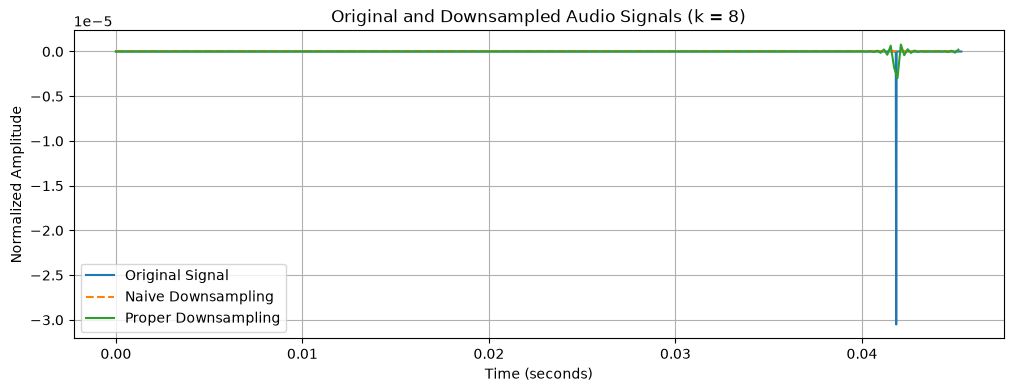

In [8]:
k = 8

# Downsample the original signal
naive = x[::k]
proper = signal.decimate(x, k, ftype="fir")

# Calculate the new sampling frequency
fs_new = fs / k

# Create time axes
t_original = np.arange(len(x)) / fs
t_naive = np.arange(len(naive)) / fs_new
t_proper = np.arange(len(proper)) / fs_new

# Plot the first 2000 original samples and corresponding downsampled samples
plt.figure(figsize=(12, 4))

plt.plot(t_original[:2000], x[:2000], label="Original Signal")
plt.plot(t_naive[:250], naive[:250], "--", label="Naive Downsampling")
plt.plot(t_proper[:250], proper[:250], label="Proper Downsampling")

plt.title("Original and Downsampled Audio Signals (k = 8)")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.legend()
plt.grid(True)
plt.show()

**Why can aliasing heard in the naive version not be removed afterwards?**

Aliasing cannot be removed after sampling because high-frequency components are folded into lower frequencies during the sampling process.

Once these frequency components overlap, it becomes difficult or impossible to distinguish the original frequencies from the aliased frequencies.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to prevent aliasing from occurring.

### Task 2.3: Uniform Quantization
In this task, a uniform quantizer is implemented using Python.
A 3-bit quantizer is used to convert a sinusoidal signal into
discrete amplitude levels. The quantization error is also
calculated and visualized.

In [9]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits

    q = np.round(x / delta) * delta

    return np.clip(q, -full_scale, full_scale - delta)

In [10]:
fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99 * np.sin(2 * np.pi * 300 * t)

print("Sampling Frequency:", fs, "Hz")
print("Number of Samples:", len(x))
print("Signal Duration:", len(x) / fs, "seconds")

Sampling Frequency: 8000 Hz
Number of Samples: 80
Signal Duration: 0.01 seconds


In [11]:
xq = quantize(x, 3)

print("Original Signal Samples:")
print(x[:10])

print("\nQuantized Signal Samples:")
print(xq[:10])

print("\nQuantization Step Size:")
print(2 / 2**3, "V")

Original Signal Samples:
[0.         0.23111091 0.44945059 0.64295357 0.80092682 0.91464074
 0.97781146 0.98694816 0.94154595 0.84411376]

Quantized Signal Samples:
[0.   0.25 0.5  0.75 0.75 0.75 0.75 0.75 0.75 0.75]

Quantization Step Size:
0.25 V


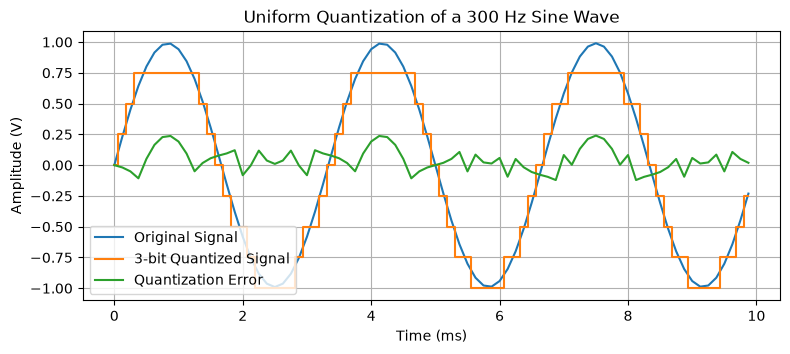

In [12]:
plt.plot(t * 1e3, x, label="Original Signal")
plt.step(t * 1e3, xq, where="mid", label="3-bit Quantized Signal")
plt.plot(t * 1e3, x - xq, label="Quantization Error")

plt.title("Uniform Quantization of a 300 Hz Sine Wave")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.grid(True)
plt.show()

**Observation and Discussion**

The original sinusoidal signal has continuously varying amplitude values. After applying a 3-bit uniform quantizer, the signal is represented using eight discrete quantization levels.

The quantized signal has a staircase appearance because each original sample is mapped to the nearest available quantization level.

The difference between the original and quantized signals is called quantization error. In this experiment, the quantization step size is 0.25 V.

Therefore, increasing the number of bits provides more quantization levels and generally reduces quantization error.

### Task 2.4: Verification of the 6 dB-per-bit Rule

In this task, the measured SQNR is calculated for different
quantizer resolutions and compared with the theoretical
SQNR equation.

In [13]:
bits = np.arange(2, 17, 2)

meas = [
    10 * np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

print("Bits:", bits)
print("Measured SQNR (dB):", meas)

Bits: [ 2  4  6  8 10 12 14 16]
Measured SQNR (dB): [np.float64(9.601454182214168), np.float64(23.576712120713314), np.float64(36.81117032372333), np.float64(48.93266972314613), np.float64(62.80801234676818), np.float64(72.83598272192836), np.float64(88.13252320131427), np.float64(98.90533146414907)]


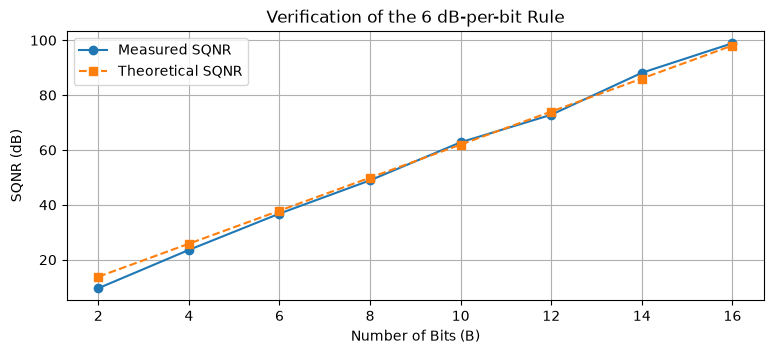

In [14]:
# Calculate theoretical SQNR
theoretical = 6.02 * bits + 1.76

# Plot measured and theoretical SQNR
plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

**Observation and Discussion**

The graph shows that SQNR increases as the number of quantization bits increases.

The measured SQNR values are generally close to the theoretical values, although some differences are observed.

The theoretical relationship indicates that adding one bit increases SQNR by approximately 6.02 dB.

The measured results may differ from theoretical values because the test signal does not perfectly satisfy all the assumptions used in deriving the theoretical SQNR equation.

Therefore, the experiment demonstrates that increasing quantization resolution improves signal quality by reducing quantization noise.

**Analysis Question 3:**

The theoretical SQNR increases by approximately 6.02 dB whenever one additional bit is added.

The measured results also show an overall increase in SQNR as the number of bits increases. However, the measured increase is not exactly 6.02 dB per bit because of the characteristics of the test signal and actual quantization error.

Therefore, the measurement supports the general 6 dB-per-bit rule, although it does not match the theoretical value exactly at every resolution.

### Task 2.5: Quantization of Real Voice Signal

In this task, the recorded voice signal is quantized using
4-bit, 8-bit, and 12-bit resolutions.

The quantized signals are compared with the original voice
recording by listening to their audio quality and calculating
their Signal-to-Quantization-Noise Ratio (SQNR).

In [15]:
# Load the original voice recording
fs_voice, voice = wavfile.read("myvoice.wav")

# Convert stereo audio to mono if necessary
if voice.ndim > 1:
    voice = voice.mean(axis=1)

# Convert audio samples to floating-point values
voice = voice.astype(float)

# Normalize the voice signal
voice = voice / np.max(np.abs(voice))

print("Voice Sampling Frequency:", fs_voice, "Hz")
print("Number of Samples:", len(voice))
print("Duration:", len(voice) / fs_voice, "seconds")

Voice Sampling Frequency: 44100 Hz
Number of Samples: 225792
Duration: 5.12 seconds


In [16]:
# Quantize voice signal using different bit resolutions
voice_4bit = quantize(voice, 4)
voice_8bit = quantize(voice, 8)
voice_12bit = quantize(voice, 12)

print("Voice quantization completed.")

print("4-bit samples:", voice_4bit[:10])
print("8-bit samples:", voice_8bit[:10])
print("12-bit samples:", voice_12bit[:10])

Voice quantization completed.
4-bit samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
8-bit samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
12-bit samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [17]:
print("Original Voice:")
print("Maximum amplitude:", np.max(voice))
print("Minimum amplitude:", np.min(voice))

print("\nQuantized Voice:")
print("4-bit maximum:", np.max(voice_4bit))
print("8-bit maximum:", np.max(voice_8bit))
print("12-bit maximum:", np.max(voice_12bit))

print("\nNon-zero samples:")
print("Original:", np.count_nonzero(voice))
print("4-bit:", np.count_nonzero(voice_4bit))
print("8-bit:", np.count_nonzero(voice_8bit))
print("12-bit:", np.count_nonzero(voice_12bit))

Original Voice:
Maximum amplitude: 1.0
Minimum amplitude: -0.6105227820673238

Quantized Voice:
4-bit maximum: 0.875
8-bit maximum: 0.9921875
12-bit maximum: 0.99951171875

Non-zero samples:
Original: 222621
4-bit: 80727
8-bit: 187992
12-bit: 219889


In [18]:
# Calculate SQNR for each quantized voice signal

sqnr_4bit = 10 * np.log10(
    np.sum(voice**2) / np.sum((voice - voice_4bit)**2)
)

sqnr_8bit = 10 * np.log10(
    np.sum(voice**2) / np.sum((voice - voice_8bit)**2)
)

sqnr_12bit = 10 * np.log10(
    np.sum(voice**2) / np.sum((voice - voice_12bit)**2)
)

print("Voice Signal SQNR Results")
print("-------------------------")
print("4-bit SQNR:", sqnr_4bit, "dB")
print("8-bit SQNR:", sqnr_8bit, "dB")
print("12-bit SQNR:", sqnr_12bit, "dB")

Voice Signal SQNR Results
-------------------------
4-bit SQNR: 11.821380330609056 dB
8-bit SQNR: 34.00519134136129 dB
12-bit SQNR: 58.0692023258284 dB


In [19]:
from IPython.display import Audio, display

print("Original Voice Recording")
display(Audio(voice, rate=fs_voice))

print("4-bit Quantized Voice")
display(Audio(voice_4bit, rate=fs_voice))

print("8-bit Quantized Voice")
display(Audio(voice_8bit, rate=fs_voice))

print("12-bit Quantized Voice")
display(Audio(voice_12bit, rate=fs_voice))

Original Voice Recording


4-bit Quantized Voice


8-bit Quantized Voice


12-bit Quantized Voice


### Listening Test Observations

The original voice recording was compared with its 4-bit, 8-bit, and 12-bit quantized versions.

The 4-bit recording had the highest distortion and the lowest audio clarity because it uses only 16 quantization levels.

The 8-bit recording had better clarity and less distortion than the 4-bit recording because it provides 256 quantization levels.

The 12-bit recording had the best audio quality among the quantized versions. It sounded almost similar to the original recording because it provides 4,096 quantization levels.

The listening observations agree with the measured SQNR results. The 12-bit signal had the highest SQNR of approximately 58.07 dB, while the 4-bit signal had the lowest SQNR of approximately 11.82 dB.

Therefore, increasing the number of quantization bits improves audio quality by reducing quantization noise.

**Analysis Question 5:**

The measured speech SQNR is generally lower than the theoretical full-scale sine-wave SQNR because speech signals do not maintain a constant maximum amplitude.

Speech contains silence, low-amplitude sections, and varying signal levels. Therefore, the available quantization levels may not be used as efficiently as they are with a full-scale sinusoidal signal.

As a result, the quantization noise becomes relatively significant compared to the average speech signal power, producing a lower measured SQNR.

Analysis and Discussion

### Question 1: Explanation of Aliasing

The original signal has a frequency of 7 Hz and is sampled at a sampling frequency of 10 Hz.

According to the Nyquist criterion, the Nyquist frequency is half of the sampling frequency:

\[
f_N = \frac{f_s}{2} = \frac{10}{2} = 5\,Hz
\]

Since the original signal frequency (7 Hz) is greater than the Nyquist frequency (5 Hz), aliasing occurs.

The alias frequency is calculated using:

\[
f_{\text{alias}} = |f_0-kf_s|
\]

For \(k=1\):

\[
f_{\text{alias}} = |7-10| = 3\,Hz
\]

Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling at 10 Hz. This phenomenon is called aliasing. It occurs because the sampling frequency is insufficient to represent the original signal correctly.

**Conclusion:** A 7 Hz signal sampled at 10 Hz appears as a 3 Hz signal because its frequency exceeds the Nyquist frequency of 5 Hz.

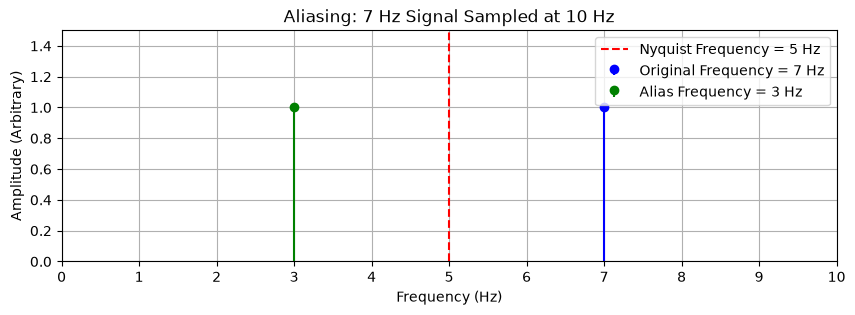

In [20]:
plt.figure(figsize=(10, 3))

# Nyquist frequency
plt.axvline(5, color="red", linestyle="--",
            label="Nyquist Frequency = 5 Hz")

# Original signal frequency
plt.stem([7], [1], linefmt="blue",
         markerfmt="bo", basefmt=" ",
         label="Original Frequency = 7 Hz")

# Alias frequency
plt.stem([3], [1], linefmt="green",
         markerfmt="go", basefmt=" ",
         label="Alias Frequency = 3 Hz")

plt.xlim(0, 10)
plt.ylim(0, 1.5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (Arbitrary)")
plt.title("Aliasing: 7 Hz Signal Sampled at 10 Hz")

plt.xticks(np.arange(0, 11, 1))
plt.grid(True)
plt.legend()
plt.show()

### Question 2: Why Aliasing Cannot Be Removed After Downsampling

Aliasing in the naive downsampling process cannot be removed afterwards because high-frequency components fold into lower frequencies when the sampling rate is reduced.

After this process, the original frequency components overlap with the aliased components. Therefore, it becomes difficult or impossible to distinguish the original signals from the aliased signals.

An anti-aliasing low-pass filter must be applied before downsampling to remove or sufficiently attenuate frequency components above the new Nyquist frequency.

In Task 2.2, the naive method used `x[::8]` without filtering, while the proper method used `signal.decimate(x, 8, ftype="fir")`, which applies filtering before reducing the sampling rate.

**Conclusion:** Aliasing should be prevented before downsampling because once aliasing occurs, the lost frequency information cannot be reliably recovered.

### Question 3: Relationship Between Quantization Bits and SQNR

According to the theoretical relationship:

\[
SQNR = 6.02B + 1.76
\]

Adding one quantization bit increases the theoretical SQNR by approximately 6.02 dB.

In my experiment, the number of bits was increased from 2 to 16 in steps of two. Therefore, the expected theoretical increase between consecutive measurements was approximately 12.04 dB.

The measured SQNR generally increased as the number of bits increased. For example, it increased from 9.60 dB at 2 bits to 23.58 dB at 4 bits, representing an increase of approximately 13.98 dB.

The measured results do not agree exactly with the theoretical values because of the characteristics of the sampled signal and variations in quantization error. However, the overall trend agrees with the theory.

**Conclusion:** Increasing the quantization resolution improves SQNR. Each additional bit theoretically increases SQNR by approximately 6.02 dB.

### Question 4: Sampling Rate and Quantization Bits for a Temperature Sensor

The temperature sensor has a maximum rate of change of 0.1 °C/s, a required resolution of 0.01 °C, and a measurement range of 0–100 °C.

**1. Selection of Sampling Rate**

A sampling frequency of 10 Hz is selected.

The sampling interval is:

\[
T_s=\frac{1}{f_s}=\frac{1}{10}=0.1\,s
\]

The maximum temperature change between consecutive samples is:

\[
\Delta T=0.1\times0.1=0.01\,^\circ C
\]

Therefore, sampling at 10 Hz allows the system to monitor temperature changes at the required resolution over time.

**2. Selection of Quantization Bits**

The required number of quantization levels is:

\[
L=\frac{100-0}{0.01}=10000
\]

The number of bits is calculated using:

\[
2^B\geq10000
\]

\[
B\geq\log_2(10000)=13.29
\]

Rounding up to the next whole number gives:

\[
B=14\ bits
\]

A 14-bit quantizer provides:

\[
2^{14}=16384\ levels
\]

This is sufficient to represent the temperature range with the required resolution.

**Conclusion:**

A sampling frequency of 10 Hz and a 14-bit quantizer are recommended. The sampling frequency provides 10 measurements per second, while the 14-bit quantizer provides enough levels to represent the 0–100 °C temperature range at approximately 0.01 °C resolution.

AI Use Declaration:
ChatGPT was used to support explanations, understand DSP concepts,
debug code, and improve the presentation of laboratory results.
All code was executed and results were checked by the student.